# DISCOVERING AI AGENT — Thực hành theo nội dung IBM [2]
Mã tự xây dựng, không phải mã nguồn do IBM phát hành. Trang [2] là bài giải thích,
không có một notebook bắt buộc. Các ví dụ làm rõ agent phản xạ, theo mục tiêu,
theo độ hữu dụng, dùng công cụ và học từ tương tác.

**Giới hạn:** bộ điều khiển công cụ dùng quy tắc Python, không sử dụng LLM và không
phải bản tái lập thí nghiệm ReAct. Dữ liệu đơn hàng hoàn toàn giả lập.
Phần Q-learning là mở rộng liên hệ [4], không thay thế nội dung IBM.

Nguồn: https://www.ibm.com/think/topics/ai-agents ;
https://cloud.google.com/discover/what-are-ai-agents ;
https://www.mckinsey.com/featured-insights/mckinsey-explainers/what-is-an-ai-agent ;
https://www.gatsby.ucl.ac.uk/~dayan/papers/cjch.pdf

Chọn Python 3, Restart Kernel & Run All. Không cần API key, Internet hay GPU.

In [1]:
import sys, json, random, statistics, platform
from collections import deque, defaultdict
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt

print("Python:", platform.python_version())
print("Matplotlib:", matplotlib.__version__)
print("Data: synthetic | LLM: none | external API: none")
print("Experiments: reflex, goal/utility, tools, Q-learning")

Python: 3.12.0
Matplotlib: 3.11.1
Data: synthetic | LLM: none | external API: none
Experiments: reflex, goal/utility, tools, Q-learning


## 1. Agent phản xạ: robot hút bụi hai phòng
Quan sát gồm vị trí và trạng thái bẩn ở phòng hiện tại. Agent không biết trực tiếp
phòng còn lại; quy tắc sạch thì di chuyển có thể làm robot lặp lại khi cả hai phòng
đều sạch. Giới hạn 8 bước để minh họa điều kiện dừng, không gán khả năng nhớ cho nó.

In [2]:
def reflex(position, dirty_here):
    if dirty_here:
        return "SUCK"
    return "RIGHT" if position == "A" else "LEFT"

def vacuum_run(start, a_dirty, b_dirty, budget=8):
    dirty = {"A": a_dirty, "B": b_dirty}
    pos, trace = start, []
    for _ in range(budget):
        action = reflex(pos, dirty[pos])
        trace.append((pos, action))
        if action == "SUCK":
            dirty[pos] = False
        else:
            pos = "B" if pos == "A" else "A"
    return not any(dirty.values()), trace

cases = [(p, a, b) for p in "AB"
         for a in (False, True) for b in (False, True)]
cleaned = sum(vacuum_run(*c)[0] for c in cases)
print(f"Clean after 8 actions: {cleaned}/{len(cases)}")
print("Trace (A, dirty, dirty):", vacuum_run("A", True, True)[1])
print("All clean still moves:", vacuum_run("A", False, False)[1][:4])
assert cleaned == 8

Clean after 8 actions: 8/8
Trace (A, dirty, dirty): [('A', 'SUCK'), ('A', 'RIGHT'), ('B', 'SUCK'), ('B', 'LEFT'), ('A', 'RIGHT'), ('B', 'LEFT'), ('A', 'RIGHT'), ('B', 'LEFT')]
All clean still moves: [('A', 'RIGHT'), ('B', 'LEFT'), ('A', 'RIGHT'), ('B', 'LEFT')]


## 2. Agent theo mục tiêu và độ hữu dụng
Ba tuyến giả lập cùng tới đích. Goal-based chỉ lọc tuyến đạt mục tiêu và giới hạn;
utility-based xếp hạng bằng chi phí tổng hợp. Hệ số 0,5 có đơn vị nghìn đồng/phút,
do người thiết kế chọn, không phải hệ số được học.

In [3]:
routes = [
    {"name": "R1", "reaches_goal": True, "minutes": 20, "fee": 40},
    {"name": "R2", "reaches_goal": True, "minutes": 35, "fee": 0},
    {"name": "R3", "reaches_goal": True, "minutes": 25, "fee": 10},
    {"name": "R4", "reaches_goal": False, "minutes": 10, "fee": 0},
]
feasible = [r for r in routes if r["reaches_goal"]]
def route_cost(route, value_of_time):
    return route["fee"] + value_of_time * route["minutes"]

print("Goal-feasible:", [r["name"] for r in feasible])
for weight in (0.5, 10.0):
    best = min(feasible, key=lambda r: route_cost(r, weight))
    print(f"Time value={weight}: choose {best['name']}, "
          f"cost={route_cost(best, weight):.1f} thousand VND")
assert min(feasible, key=lambda r: route_cost(r, 0.5))["name"] == "R2"
assert min(feasible, key=lambda r: route_cost(r, 10.0))["name"] == "R1"

Goal-feasible: ['R1', 'R2', 'R3']
Time value=0.5: choose R2, cost=17.5 thousand VND
Time value=10.0: choose R1, cost=240.0 thousand VND


## 3. Agent dùng công cụ: trợ lý tra cứu và hoàn tiền
Mục tiêu đầu vào là dữ liệu có cấu trúc. Controller chọn hành động tiếp theo theo
quan sát vừa nhận. Bộ nhớ là danh sách sự kiện; thêm log không phải cập nhật trọng
số mô hình. Quyền xem đơn và quyền hoàn tiền được kiểm tra trong công cụ.

In [4]:
ORDERS = {
    "DH001": {"owner": "SV01", "paid": 150000, "status": "delivered"},
    "DH002": {"owner": "SV01", "paid": 800000, "status": "delivered"},
    "DH003": {"owner": "SV02", "paid": 90000, "status": "delivered"},
    "DH004": {"owner": "SV01", "paid": 70000, "status": "shipping"},
}
REFUNDED = set()
def lookup_order(order_id, user):
    order = ORDERS.get(order_id)
    if order is None: return {"error": "NOT_FOUND"}
    if order["owner"] != user: return {"error": "FORBIDDEN"}
    return dict(order)

def refund_order(order_id, user, approved=False):
    order = lookup_order(order_id, user)
    if "error" in order: return order["error"]
    if order["status"] != "delivered": return "NOT_ELIGIBLE"
    if order["paid"] > 500000 and not approved:
        return "NEEDS_APPROVAL"
    if order_id in REFUNDED: return "ALREADY_REFUNDED"
    REFUNDED.add(order_id)
    return "REFUNDED"

print("Synthetic orders:", len(ORDERS))
print("Approval threshold: 500000 VND | ownership check: enabled")

Synthetic orders: 4
Approval threshold: 500000 VND | ownership check: enabled


In [5]:
class ToolAgent:
    def __init__(self, user, max_steps=4):
        self.user, self.max_steps = user, max_steps
        self.memory = []

    def run(self, order_id, intent="refund", approved=False):
        observation = None
        for step in range(self.max_steps):
            if observation is None:
                action = "lookup_order"
                observation = lookup_order(order_id, self.user)
            elif "error" in observation:
                return observation["error"]
            elif intent == "status":
                return observation["status"]
            elif intent != "refund":
                return "UNSUPPORTED_INTENT"
            else:
                action = "refund_order"
                result = refund_order(order_id, self.user, approved)
                self.memory.append({"step": step + 1,
                    "tool": action, "observation": result})
                return result
            self.memory.append({"step": step + 1,
                "tool": action, "observation": observation})
        return "STEP_LIMIT"

print("Controller ready; bounded tool loop; no language model.")

Controller ready; bounded tool loop; no language model.


In [6]:
REFUNDED.clear()
agent = ToolAgent("SV01")
result = agent.run("DH001")
print("Final:", result)
for event in agent.memory:
    print(json.dumps(event, ensure_ascii=False))
print("Persistent refund state:", sorted(REFUNDED))
print("Retry same request:", agent.run("DH001"))
assert result == "REFUNDED"
assert len(REFUNDED) == 1

Final: REFUNDED
{"step": 1, "tool": "lookup_order", "observation": {"owner": "SV01", "paid": 150000, "status": "delivered"}}
{"step": 2, "tool": "refund_order", "observation": "REFUNDED"}
Persistent refund state: ['DH001']
Retry same request: ALREADY_REFUNDED


### Kiểm tra chức năng và tình huống biên
Mỗi trường hợp được tách trạng thái để tránh ảnh hưởng chéo. `approved=True` mô
phỏng xác nhận của nhân viên; hệ thống thật phải lấy quyền này từ dịch vụ xác thực,
không cho người dùng tự gửi boolean để cấp quyền.

In [7]:
checks = [
    ("normal refund", "DH001", "refund", False, 4, "REFUNDED"),
    ("large refund", "DH002", "refund", False, 4, "NEEDS_APPROVAL"),
    ("approved", "DH002", "refund", True, 4, "REFUNDED"),
    ("other owner", "DH003", "refund", False, 4, "FORBIDDEN"),
    ("missing", "DH999", "refund", False, 4, "NOT_FOUND"),
    ("shipping", "DH004", "refund", False, 4, "NOT_ELIGIBLE"),
    ("status", "DH004", "status", False, 4, "shipping"),
    ("unknown intent", "DH001", "delete", False, 4, "UNSUPPORTED_INTENT"),
    ("step limit", "DH001", "refund", False, 1, "STEP_LIMIT"),
]
for label, oid, intent, approval, limit, expected in checks:
    REFUNDED.clear()
    actual = ToolAgent("SV01", limit).run(oid, intent, approval)
    assert actual == expected, (label, actual, expected)
    print(f"PASS {label:15s} -> {actual}")
REFUNDED.clear()
assert refund_order("DH003", "SV01", True) == "FORBIDDEN"
assert refund_order("DH001", "SV01") == "REFUNDED"
assert refund_order("DH001", "SV01") == "ALREADY_REFUNDED"
print("PASS direct authorization + duplicate refund protection")
print("12/12 checks passed (9 scenarios + 3 direct assertions)")

PASS normal refund   -> REFUNDED
PASS large refund    -> NEEDS_APPROVAL
PASS approved        -> REFUNDED
PASS other owner     -> FORBIDDEN
PASS missing         -> NOT_FOUND
PASS shipping        -> NOT_ELIGIBLE
PASS status          -> shipping
PASS unknown intent  -> UNSUPPORTED_INTENT
PASS step limit      -> STEP_LIMIT
PASS direct authorization + duplicate refund protection
12/12 checks passed (9 scenarios + 3 direct assertions)


## 4. Mở rộng: learning agent bằng Q-learning
GridWorld tự thiết kế 5×5, 4 hành động. Tường giữ nguyên vị trí và phạt −3;
ô thường −1; bẫy −20 và kết thúc; đích +20 và kết thúc. Tối đa 100 bước.
Q-learning theo Watkins & Dayan (1992), không sao chép mê cung của [4].

In [8]:
SIZE, START, GOAL = 5, (0, 0), (4, 4)
WALLS = {(1, 1), (1, 3), (2, 3), (3, 1)}
TRAPS = {(2, 2), (4, 1)}
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]
def transition(state, action):
    dr, dc = MOVES[action]
    nxt = (state[0] + dr, state[1] + dc)
    if not (0 <= nxt[0] < SIZE and 0 <= nxt[1] < SIZE) or nxt in WALLS:
        return state, -3, False
    if nxt in TRAPS: return nxt, -20, True
    if nxt == GOAL: return nxt, 20, True
    return nxt, -1, False

def shortest_path():
    queue, visited = deque([(START, [START])]), {START}
    while queue:
        state, path = queue.popleft()
        if state == GOAL: return path
        for action in range(4):
            nxt, _, _ = transition(state, action)
            if nxt not in visited and nxt not in TRAPS:
                visited.add(nxt)
                queue.append((nxt, path + [nxt]))

optimal = shortest_path()
print("BFS shortest safe path:", optimal)
print("Optimal number of moves:", len(optimal) - 1)
assert len(optimal) - 1 == 8

BFS shortest safe path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]
Optimal number of moves: 8


In [9]:
def train(seed, episodes=2500):
    rng, q, returns = random.Random(seed), defaultdict(lambda: [0.0]*4), []
    for episode in range(episodes):
        state, total = START, 0
        epsilon = max(0.05, 0.997 ** episode)
        for _ in range(100):
            if rng.random() < epsilon:
                action = rng.randrange(4)
            else:
                best = max(q[state])
                ties = [a for a in range(4) if q[state][a] == best]
                action = rng.choice(ties)
            nxt, reward, done = transition(state, action)
            target = reward if done else reward + 0.95 * max(q[nxt])
            q[state][action] += 0.2 * (target - q[state][action])
            state, total = nxt, total + reward
            if done: break
        returns.append(total)
    return q, returns

trained = {seed: train(seed) for seed in range(5)}
print("Seeds: 0..4 | episodes per seed: 2500 | max steps: 100")
for seed, (_, rewards) in trained.items():
    print(f"seed={seed}: first100={statistics.mean(rewards[:100]):.2f}, "
          f"last100={statistics.mean(rewards[-100:]):.2f}")

Seeds: 0..4 | episodes per seed: 2500 | max steps: 100
seed=0: first100=-57.88, last100=12.09
seed=1: first100=-54.95, last100=12.39
seed=2: first100=-53.30, last100=11.94
seed=3: first100=-50.33, last100=12.19
seed=4: first100=-52.72, last100=12.29


In [10]:
def rollout(q=None, seed=1000):
    rng, state, total, path = random.Random(seed), START, 0, [START]
    for step in range(1, 101):
        action = rng.randrange(4) if q is None else max(range(4), key=lambda a: q[state][a])
        state, reward, done = transition(state, action)
        total += reward
        path.append(state)
        if done: return state == GOAL, step, total, path
    return False, 100, total, path

rows = []
for seed, (q, _) in trained.items():
    ok, steps, total, path = rollout(q)
    rows.append({"seed": seed, "success": ok, "steps": steps, "return": total})
    print(f"Q seed={seed}: success={ok}, steps={steps}, return={total}")
baseline = [rollout(seed=1000+i) for i in range(200)]
success_rate = sum(r[0] for r in baseline) / len(baseline)
print(f"Random policy: success={success_rate:.1%} (200 episodes)")
print(f"Random mean return={statistics.mean(r[2] for r in baseline):.2f}")
assert all(r["success"] and r["steps"] == 8 for r in rows)
print("Greedy path seed=0:", rollout(trained[0][0])[3])
metrics = {"q_learning": rows, "random_success_rate": success_rate,
           "random_mean_return": statistics.mean(r[2] for r in baseline),
           "bfs_steps": len(optimal)-1}
Path("metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

Q seed=0: success=True, steps=8, return=13
Q seed=1: success=True, steps=8, return=13
Q seed=2: success=True, steps=8, return=13
Q seed=3: success=True, steps=8, return=13
Q seed=4: success=True, steps=8, return=13
Random policy: success=9.0% (200 episodes)
Random mean return=-76.33
Greedy path seed=0: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]


555

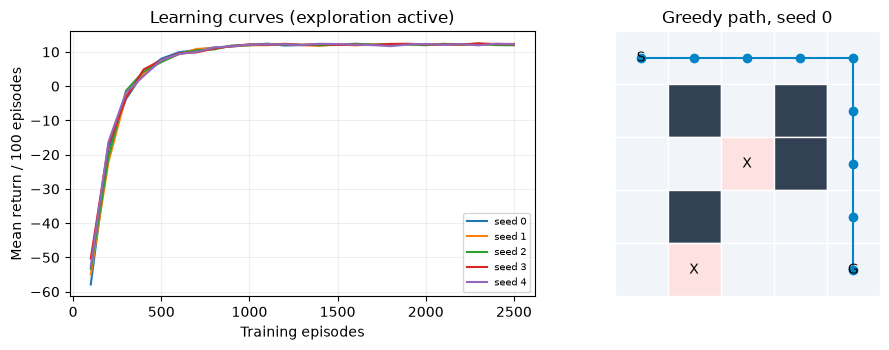

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for seed, (_, rewards) in trained.items():
    smooth = [statistics.mean(rewards[i:i+100]) for i in range(0, 2500, 100)]
    axes[0].plot(range(100, 2501, 100), smooth, label=f"seed {seed}")
axes[0].set(xlabel="Training episodes", ylabel="Mean return / 100 episodes",
            title="Learning curves (exploration active)")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.2)
for r in range(SIZE):
    for c in range(SIZE):
        state = (r, c)
        color = "#334155" if state in WALLS else "#fee2e2" if state in TRAPS else "#f1f5f9"
        axes[1].add_patch(plt.Rectangle((c, SIZE-1-r), 1, 1, fc=color, ec="white"))
        label = "G" if state == GOAL else "S" if state == START else "X" if state in TRAPS else ""
        axes[1].text(c+0.5, SIZE-r-0.5, label, ha="center", va="center")
path = rollout(trained[0][0])[3]
axes[1].plot([c+0.5 for r,c in path], [SIZE-r-0.5 for r,c in path], "o-", color="#0284c7")
axes[1].set(xlim=(0,5), ylim=(0,5), title="Greedy path, seed 0")
axes[1].set_aspect("equal")
axes[1].axis("off")
fig.tight_layout()
fig.savefig("learning_results.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Kết luận và giới hạn
- Bộ điều khiển công cụ dùng trạng thái quan sát được để chọn hành động, nhưng
  mục tiêu là dữ liệu cấu trúc và chính sách do lập trình viên viết.
- Cả 5 nhóm agent có thể được giải thích mà không bắt buộc dùng LLM.
- Q-learning thực sự cập nhật bảng Q. Log công cụ và bảng Q là hai loại bộ nhớ khác nhau.
- 5 seed chỉ đánh giá độ lặp lại trong một bản đồ cố định; chưa chứng minh khả năng
  tổng quát hóa sang bản đồ mới. Baseline ngẫu nhiên gồm 200 lượt độc lập.
- Đường đi được đối chiếu BFS, không gọi kết quả tối ưu chỉ vì tổng thưởng tăng.
- Hệ thống hoàn tiền thật cần xác thực, giao dịch bền vững, chống đua đồng thời,
  idempotency key, audit và kiểm định bảo mật; tập hợp Python chỉ là mô phỏng.